# plot_erosion_energies.py

*Generated from `plot_erosion_energies.py` by `tools/build_notebooks.py`. Edit the script, then rebuild.*

```text
plot_erosion_energies.py - one figure per crystal plane, all He energies overlaid,
from the erosion.csv files written by ovito_insertion_movies.py.

    left axis  : surface regression     light blue (low E) ... purple (high E)
    right axis : cumulative sputtering  light orange ...      dark red

Files: PLANE_FILES per plane (e.g. erosion_WC_basal_C_{energy}eV.csv), else
CSV_TEMPLATE (erosion_{plane}{energy}.csv).  FIGURE_MODE: "combined" (twin-axis
erosion_combined_<plane>.png), "separate" (erosion_regression_<plane>.png and
erosion_sputtering_<plane>.png) or "both".

    python plot_erosion_energies.py [--dir CSVs] [--planes bC bW] [--mode separate]
        --trend on (fit + print equations)   --curves trend (fits only)
        --trend-figures (extra fits-only copies)   --x-axis ps   --show
        --reg-col regression_A --reg-smooth N --reg-label TEXT --suffix _front
        --reg-ylim LO HI  --sput-ylim LO HI  --xlim LO HI   (shared axes for slides)

Requires numpy, matplotlib.
```

In [ ]:
# settings (the same as the script's command line)
import os, sys
SCRIPT = 'plot_erosion_energies.py'
NB_CSV = "."          # erosion_WC_basal_C_50eV.csv, ... (see PLANE_FILES)
NB_OUT = "nb_figs"
os.makedirs(NB_OUT, exist_ok=True)
ARGS = ["--dir", NB_CSV, "--out", NB_OUT]
sys.argv = [SCRIPT] + ARGS
__file__ = os.path.abspath(SCRIPT)

In [2]:
import argparse
import csv
import os
import sys

import numpy as np
import matplotlib

if "--show" not in sys.argv:          # headless-safe unless a window is asked for
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_hex, to_rgb
from matplotlib.lines import Line2D

In [3]:
# ===========================================================================
# 1. WHAT TO PLOT
# ===========================================================================
# Plane keys: "bC", "bW", "pr", "W001" (current runs); "p" / "b" for old
# erosion_p100.csv-style files.
PLANES = ["bC", "bW", "pr", "W001"]
PLANE_NAMES = {"p": "prism plane", "b": "basal plane",
               "bC": "WC basal (C-terminated)",
               "bW": "WC basal (W-terminated)",
               "pr": "WC prism",
               "W001": "W(001)"}

ENERGIES = [50, 100, 200]            # eV; add/remove freely, keep ascending
ENERGY_UNIT = "eV"

CSV_DIR = "."                                     # where the CSVs live
CSV_TEMPLATE = "erosion_{plane}{energy}.csv"      # -> erosion_p100.csv
# Per-plane file names; a plane not listed here falls back to CSV_TEMPLATE.
PLANE_FILES = {
    "bC": "erosion_WC_basal_C_{energy}eV.csv",
    "bW": "erosion_WC_basal_W_{energy}eV.csv",
    "pr": "erosion_WC_prism_{energy}eV.csv",
    "W001": "erosion_W001_{energy}eV.csv",
}
OUT_DIR = "."
SKIP_MISSING = True                  # True = warn and continue; False = error

# "combined" (twin axis) | "separate" (two figures) | "both"
FIGURE_MODE = "separate"

OUT_TEMPLATE = "erosion_combined_{plane}.png"       # combined figure
REG_OUT_TEMPLATE = "erosion_regression_{plane}.png"  # regression-only figure
SPUT_OUT_TEMPLATE = "erosion_sputtering_{plane}.png"  # sputtering-only figure

# Which columns to read (must match the CSV header)
COL_CYCLE = "cycle"
# Regression column of the current CSVs:
#   "order_deficit_A" (R_D, default) | "regression_A" (front R) | "growth_A" (G)
COL_REG = "order_deficit_A"
COL_SPUT = {"W": "sputtered_W", "C": "sputtered_C"}

PLOT_REGRESSION = True
SPUTTER_SPECIES = ["C"]              # ["C"], ["W"], or ["W", "C"]
# Per-plane override, e.g. pure W has no carbon to sputter.
PLANE_SPUTTER_SPECIES = {"W001": ["W"]}
                                     # ("C" only is usually the readable choice)

In [4]:
# ===========================================================================
# 2. COLORS: edit the stops; everything else follows
# ===========================================================================
# Regression family: light blue -> blue -> purple
REG_COLOR_STOPS = ["#a6cee3", "#2b7bba", "#6a3d9a"]
# Sputtering family: light orange -> dark red (one stop per energy with "index")
SPUT_COLOR_STOPS = ["#fdd0a2", "#f4a04a", "#e2711d", "#c1121f", "#7d0a12"]

# Spread of the energies along the gradient:
#   "log"   by log10(E)
#   "index" equal steps by position in ENERGIES (better separated shades)
COLOR_SPACING = "log"
# Per-family override; None inherits COLOR_SPACING.
REG_COLOR_SPACING = None
SPUT_COLOR_SPACING = "index"
COLOR_RANGE = (0.0, 1.0)             # clip the gradient, e.g. (0.15, 0.95)

# Axis-decoration colors (spines, ticks, y-labels). None = middle of the ramp.
REG_AXIS_COLOR = 'black'             # or None, "#2b7bba"
SPUT_AXIS_COLOR = 'black'            # or None, "#e07b1f"

# Per-energy color overrides, e.g. {100: "#00429d"}; leave empty for the ramp
REG_COLOR_OVERRIDE = {}
SPUT_COLOR_OVERRIDE = {}

In [5]:
# ===========================================================================
# 3. LINE / MARKER STYLE
# ===========================================================================
REG_LINE_KW = dict(                  # applied to every regression curve
    linestyle="-",
    linewidth=1.4,
    alpha=0.90,
    marker="",                       # "" = none; try "o", "s", "^"
    markersize=3.0,
    markevery=25,
    zorder=3,
)
SPUT_LINE_KW = dict(                 # applied to every sputtering curve
    linestyle="-",
    linewidth=1.4,
    alpha=0.90,
    marker="",
    markersize=3.0,
    markevery=25,
    zorder=2,
)
# Linestyle per sputtered species (overrides SPUT_LINE_KW["linestyle"])
SPUT_SPECIES_LINESTYLE = {"C": "-", "W": "--"}

# Line width can also scale with energy (1.0 = same width for all energies)
LINEWIDTH_ENERGY_SCALE = 1.0         # e.g. 1.25 -> highest energy 25% thicker

# Marker shape per energy, in ENERGIES order (survives overlap and greyscale); [] = none.
REG_MARKERS = []
SPUT_MARKERS = []                    # e.g. ["o", "s", "^", "D", "v"]
MARKER_EVERY = 150                   # plot a marker every N points
MARKER_SIZE = 4.5

# Label each curve at its right-hand end instead of a legend.
END_LABELS = False
END_LABEL_REPLACES_LEGEND = True     # drop the legend when labels are on
END_LABEL_FONTSIZE = 9
END_LABEL_OFFSET = (6, 0)            # (dx, dy) in points from the curve end
END_LABEL_MARGIN = 0.14              # extra x-axis room for the labels

# Smoothing (centered rolling mean; 1 = raw data)
REG_SMOOTH = 1
SPUT_SMOOTH = 1
RAW_UNDERLAY = True                  # faint raw trace behind a smoothed line
RAW_UNDERLAY_ALPHA = 0.18

In [6]:
# ===========================================================================
# 4. FIGURE / AXES
# ===========================================================================
FIG_SIZE = (8.4, 5.2)                # inches (width, height), combined figure
SEPARATE_FIG_SIZE = (7.2, 4.6)       # inches, regression-only / sputtering-only
FIG_DPI = 200
SAVE_ALSO_PDF = False                # write a vector copy next to the PNG

TITLE_TEMPLATE = "Surface regression and cumulative sputtering - {plane}"
REG_TITLE_TEMPLATE = "Surface regression - {plane}"
SPUT_TITLE_TEMPLATE = "Cumulative sputtering - {plane}"
REG_Y_LABEL = "Surface regression (\u00c5)"
SPUT_Y_LABEL = "Cumulative sputtered atoms"

In [7]:
# --- X AXIS ----------------------------------------------------------------
# Display only: "cycle" | "ps" (cycle * T_CYCLE_PS) | "ns".  Fits, slopes,
# ranges and printed equations stay in cycles (slopes are per impact).
X_AXIS = "ns"
T_CYCLE_PS = 20.0                    # insertion-to-insertion interval, ps
X_AXIS_LABELS = {"cycle": "Impact cycle", "ps": "Time (ps)", "ns": "Time (ns)"}
X_LABEL = None                       # None = from X_AXIS_LABELS

X_LIM = None                         # None = auto, e.g. (0, 3000), in displayed units
REG_Y_LIM = None                     # None = auto, e.g. (-2.0, 0.1); --reg-ylim
SPUT_Y_LIM = None                    # None = auto, or e.g. (0, 400)

In [8]:
# --- second x axis: fluence --------------------------------------------
# He m^-2 along the top: one He per cycle over the impact area (central
# 2/3 x 2/3 of the cell; IMPACT AREA in the LAMMPS log).
FLUENCE_AXIS = True
IMPACT_AREA_A2 = {"bC": 3567.0, "bW": 3567.0, "b": 3567.0,
                  "pr": 3420.0, "p": 3420.0,
                  "W001": 3490.0}    # W(001): estimate for a = 3.165 A;
                                     # use the logged IMPACT AREA
FLUENCE_EXP = 19                     # axis shown in units of 10^FLUENCE_EXP
FLUENCE_LABEL = r"Fluence ($10^{%d}$ He m$^{-2}$)"

TITLE_KW = dict(fontsize=13)
LABEL_KW = dict(fontsize=11.5)
TICK_KW = dict(labelsize=10)

GRID_ON = True
GRID_KW = dict(color="#b8b8b8", linestyle=":", linewidth=0.8, alpha=0.7)

# Optional: force every curve to start at 0 regression (removes any offset in
# the first recorded cycle so the energies are directly comparable)
BASELINE_ZERO = False
# Optional: drop the first N cycles (the initial spike in the single-run plot)
SKIP_FIRST_CYCLES = 0

In [9]:
# ===========================================================================
# 5. LEGENDS (one per colour family)
# ===========================================================================
SPLIT_LEGENDS = True
LEGEND_KW = dict(frameon=True, framealpha=0.9, fontsize=9, handlelength=2.2,
                 borderpad=0.5, labelspacing=0.35)
REG_LEGEND_TITLE = "Regression"
SPUT_LEGEND_TITLE = "Sputtered {species}"
REG_LEGEND_LOC = "lower left"
SPUT_LEGEND_LOC = "upper left"
LEGEND_TITLE_KW = dict(fontsize=9)
LEGEND_ZORDER = 20                   # keeps the legends above every curve
LEGEND_NCOL = 1
# Single-legend fallback (SPLIT_LEGENDS = False)
COMBINED_LEGEND_LOC = "upper center"
COMBINED_LEGEND_NCOL = 2
# Legend placement on the standalone (FIGURE_MODE = "separate") figures
SOLO_REG_LEGEND_LOC = "lower left"
SOLO_SPUT_LEGEND_LOC = "upper left"
SOLO_LEGEND_NCOL = 1

In [10]:
# ===========================================================================
# 6. TRENDLINES
# ===========================================================================
TREND_REGRESSION = False          # fit the regression curves
TREND_SPUTTERING = False            # fit the cumulative-sputtering curves

# Fit model: "linear" (y = m*x + b) | "poly" (TREND_DEGREE) | "power" (y = a*x^b,
# log-log; needs x, y > 0)
TREND_MODEL = "linear"
TREND_DEGREE = 2                     # only used when TREND_MODEL = "poly"
# Power fits need y > 0; below this fraction of usable points, fit linear instead.
TREND_POWER_MIN_FRACTION = 0.75

# Force the sputtering fit through (0, 0) -- physically sensible for a
# cumulative count. Linear model only; ignored for "poly"/"power".
TREND_SPUT_THROUGH_ORIGIN = False
TREND_REG_THROUGH_ORIGIN = False

# Fit window in impact cycles: None = every point, or (start, end) to skip an
# initial transient, e.g. (200, None) fits from cycle 200 onward.
TREND_FIT_RANGE = None
TREND_EXTEND = True                  # draw the fit across the full data range
                                     # (False = only over the fitted window)

TREND_LINE_KW = dict(                # style of the fitted lines
    linestyle="--",
    linewidth=1.1,
    alpha=0.85,
    zorder=5,
)
TREND_COLOR = None                   # None = match each energy's curve color
TREND_COLOR_DARKEN = 0.25             # 0 = same shade, 0.3 = 30% darker

# Fits in the legend: "none" | "slope" (append to the data label) | "entry"
TREND_LEGEND_MODE = "none"
TREND_SLOPE_FMT = "%.3g"             # used by "slope" / "entry"

TREND_PRINT = True                   # print every equation to the terminal
TREND_EQ_FMT = "%.5g"                # coefficient formatting in the equations
TREND_PRINT_R2 = True

In [11]:
# --- per-energy overrides: a model name, or a dict of model, degree,
# fit_range, through_origin, line_kw.  Example:
#   TREND_REG_OVERRIDE = {1000: dict(model="poly", degree=2),
#                          200: dict(fit_range=(300, None))}
TREND_REG_OVERRIDE = {}
# For sputtering the key may be an energy (applies to every species) or a
# (species, energy) tuple, e.g. {("C", 1000): dict(model="power")}
TREND_SPUT_OVERRIDE = {}

In [12]:
# --- extrapolation: extend the fits to an absolute cycle and/or a multiple of
# each curve's length (the larger wins)
TREND_EXTRAPOLATE_TO = 10000          # e.g. 10000
TREND_EXTRAPOLATE_FACTOR = None      # e.g. 2.0 -> twice the simulated range
TREND_EXTRAP_LINE_KW = dict(         # style of the extrapolated segment only
    linestyle=":",
    alpha=0.55,
)
# Cycles at which to print the fitted value for every curve, e.g.
# [5000, 10000] -> "predict: 5000 -> -3.51, 10000 -> -7.02"
TREND_PREDICT_AT = []
TREND_PREDICT_FMT = "%.4g"

In [13]:
# --- what the figures show: "both" (data + fits) | "data" | "trend" (fits only)
CURVE_DISPLAY = "both"
# Also write a fits-only copy of every figure (TREND_ONLY_SUFFIX).
TREND_ONLY_FIGURES = False
TREND_ONLY_SUFFIX = "_fits"
TREND_ONLY_TITLE_SUFFIX = " (fits)"
# Style applied to the fits when no data is behind them -- dashes are there to
# separate a fit from its data, so a solid line usually reads better alone.
TREND_ONLY_LINE_KW = dict(
    linestyle="-",
    linewidth=1.6,
    alpha=0.95,
)
# TREND_COLOR_DARKEN exists to separate a fit from the data under it; with the
# data hidden there is nothing to separate from, so use the plain ramp color.
TREND_ONLY_USE_CURVE_COLOR = True

# ===========================================================================


_DEFAULT_SPECIES = list(SPUTTER_SPECIES)

In [14]:
# ---------------------------------------------------------------------------
# helpers
# ---------------------------------------------------------------------------
def _cmap(stops, name):
    return LinearSegmentedColormap.from_list(name, stops, N=512)


def energy_positions(energies, mode, rng):
    """Map each energy to a 0-1 position along the color ramp."""
    e = np.asarray(energies, dtype=float)
    if e.size == 1:
        t = np.array([0.5])
    elif mode == "log":
        le = np.log10(e)
        t = (le - le.min()) / (le.max() - le.min())
    else:                                    # "index"
        t = np.linspace(0.0, 1.0, e.size)
    lo, hi = rng
    return lo + t * (hi - lo)


def build_color_maps():
    """Return {energy: color} dicts for the regression and sputter families."""
    reg_pos = energy_positions(ENERGIES, REG_COLOR_SPACING or COLOR_SPACING,
                               COLOR_RANGE)
    sput_pos = energy_positions(ENERGIES, SPUT_COLOR_SPACING or COLOR_SPACING,
                                COLOR_RANGE)
    reg_cm = _cmap(REG_COLOR_STOPS, "reg")
    sput_cm = _cmap(SPUT_COLOR_STOPS, "sput")
    reg = {E: to_hex(reg_cm(p)) for E, p in zip(ENERGIES, reg_pos)}
    sput = {E: to_hex(sput_cm(p)) for E, p in zip(ENERGIES, sput_pos)}
    reg.update(REG_COLOR_OVERRIDE)
    sput.update(SPUT_COLOR_OVERRIDE)
    axis_reg = REG_AXIS_COLOR or to_hex(reg_cm(0.5 * sum(COLOR_RANGE)))
    axis_sput = SPUT_AXIS_COLOR or to_hex(sput_cm(0.5 * sum(COLOR_RANGE)))
    return reg, sput, axis_reg, axis_sput


def rolling_mean(y, window):
    y = np.asarray(y, dtype=float)
    w = int(window or 1)
    if w < 2 or y.size < 2:
        return y
    w = min(w, y.size)
    lo = w // 2
    hi = w - 1 - lo
    return np.convolve(np.pad(y, (lo, hi), mode="edge"), np.ones(w) / w,
                       mode="valid")


def as_float(seq):
    out = []
    for v in seq:
        try:
            out.append(float(v))
        except (TypeError, ValueError):
            out.append(np.nan)
    return np.array(out, dtype=float)


def load_csv(path):
    """Return {column_name: np.array} for one erosion CSV."""
    with open(path, newline="") as fh:
        rows = list(csv.DictReader(fh))
    if not rows:
        raise ValueError("no data rows in %s" % path)
    cols = {k: as_float([r.get(k) for r in rows]) for k in rows[0]
            if k is not None}

    keep = np.ones(cols[COL_CYCLE].size, dtype=bool)
    if SKIP_FIRST_CYCLES:
        keep &= cols[COL_CYCLE] > float(SKIP_FIRST_CYCLES)
    if not keep.all():
        cols = {k: v[keep] for k, v in cols.items()}
    return cols


def linewidth_for(base_lw, idx, n):
    if n < 2 or LINEWIDTH_ENERGY_SCALE == 1.0:
        return base_lw
    f = 1.0 + (LINEWIDTH_ENERGY_SCALE - 1.0) * idx / (n - 1)
    return base_lw * f


def marker_for(markers, idx):
    """Marker shape for the idx-th energy, or None when markers are off."""
    if not markers:
        return None
    return markers[idx % len(markers)]


def add_end_label(ax, x, y, text, color):
    """Annotate the right-hand end of a curve with its energy."""
    if not END_LABELS or not np.isfinite(x) or not np.isfinite(y):
        return
    ax.annotate(text, xy=(float(x), float(y)), xytext=END_LABEL_OFFSET,
                textcoords="offset points", color=color,
                fontsize=END_LABEL_FONTSIZE, va="center", ha="left",
                clip_on=False, zorder=LEGEND_ZORDER)


def energy_label(E):
    return "%g %s" % (E, ENERGY_UNIT)

In [15]:
# ---------------------------------------------------------------------------
# x axis: cycles -> X_AXIS units, applied only when drawing
# ---------------------------------------------------------------------------
def x_scale():
    """Multiplier taking one impact cycle to one unit of the displayed axis."""
    if X_AXIS == "ps":
        return float(T_CYCLE_PS)
    if X_AXIS == "ns":
        return float(T_CYCLE_PS) / 1000.0
    return 1.0                                   # "cycle"


def x_display(cycles):
    """Cycle numbers as they should appear on the axis."""
    return np.asarray(cycles, dtype=float) * x_scale()


def x_axis_label():
    return X_LABEL or X_AXIS_LABELS.get(X_AXIS, X_AXIS_LABELS["cycle"])


def add_fluence_axis(ax, plane):
    """Top x axis in fluence units, tied to the displayed bottom axis."""
    if not FLUENCE_AXIS or plane not in IMPACT_AREA_A2:
        return None
    per_cycle = 1.0 / (IMPACT_AREA_A2[plane] * 1e-20) / 10.0 ** FLUENCE_EXP
    k = per_cycle / x_scale()                 # displayed unit -> fluence unit
    top = ax.secondary_xaxis("top", functions=(lambda x: x * k,
                                               lambda f: f / k))
    top.set_xlabel(FLUENCE_LABEL % FLUENCE_EXP, **LABEL_KW)
    top.tick_params(axis="x", **TICK_KW)
    return top

In [16]:
# ---------------------------------------------------------------------------
# trendline fitting
# ---------------------------------------------------------------------------
class Fit(object):
    """One fitted trendline: the callable, the printable equation, the stats."""

    def __init__(self, model, coeffs, predict, equation, slope, r2,
                 x_lo, x_hi, npts, line_kw=None):
        self.model = model
        self.coeffs = coeffs
        self.predict = predict
        self.equation = equation
        self.slope = slope          # dy/dx (at mid-range for non-linear fits)
        self.r2 = r2
        self.x_lo = x_lo
        self.x_hi = x_hi
        self.npts = npts
        self.line_kw = line_kw or {}   # per-energy style override


def _fmt(v):
    return TREND_EQ_FMT % v


def _poly_equation(c):
    """c is highest-order-first, as returned by np.polyfit."""
    deg = len(c) - 1
    terms = []
    for i, a in enumerate(c):
        power = deg - i
        if power == 0:
            t = _fmt(abs(a))
        elif power == 1:
            t = "%s*x" % _fmt(abs(a))
        else:
            t = "%s*x^%d" % (_fmt(abs(a)), power)
        if not terms:
            terms.append(("-" if a < 0 else "") + t)
        else:
            terms.append(("- " if a < 0 else "+ ") + t)
    return "y = " + " ".join(terms)

In [17]:
def _r2(y, yhat):
    ss_res = float(np.sum((y - yhat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    if ss_tot <= 0:
        return float("nan")
    return 1.0 - ss_res / ss_tot


def fit_trend(x, y, model=None, degree=None, through_origin=False, tag="",
              fit_range="default", line_kw=None):
    """Fit x/y with the configured model. Returns a Fit, or None if it fails."""
    model = (model or TREND_MODEL).lower()
    degree = TREND_DEGREE if degree is None else degree
    if fit_range == "default":
        fit_range = TREND_FIT_RANGE

    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    m = np.isfinite(x) & np.isfinite(y)
    if fit_range:
        lo, hi = fit_range
        if lo is not None:
            m &= x >= float(lo)
        if hi is not None:
            m &= x <= float(hi)
    xf, yf = x[m], y[m]
    if xf.size < 2 or np.ptp(xf) == 0:
        return None

    if model == "power":
        pm = (xf > 0) & (yf > 0)
        need = max(2, int(TREND_POWER_MIN_FRACTION * xf.size))
        if pm.sum() < need:
            print("    %s: power fit needs x>0 and y>0 (%d/%d usable points) "
                  "- using a linear fit instead"
                  % (tag or "series", int(pm.sum()), int(xf.size)))
            model = "linear"
        else:
            b, log_a = np.polyfit(np.log(xf[pm]), np.log(yf[pm]), 1)
            a = float(np.exp(log_a))

            def predict(xx, a=a, b=b):
                xx = np.asarray(xx, dtype=float)
                out = np.full(xx.shape, np.nan)
                ok = xx > 0
                out[ok] = a * xx[ok] ** b
                return out

            eq = "y = %s*x^%s" % (_fmt(a), _fmt(b))
            xmid = float(np.median(xf[pm]))
            slope = a * b * xmid ** (b - 1.0)
            return Fit("power", (a, b), predict, eq, slope,
                       _r2(yf[pm], predict(xf[pm])), float(xf.min()),
                       float(xf.max()), int(pm.sum()), line_kw)

    if model == "poly" and degree > 1:
        c = np.polyfit(xf, yf, int(degree))
        predict = np.poly1d(c)
        xmid = float(np.median(xf))
        slope = float(np.polyder(np.poly1d(c))(xmid))
        return Fit("poly%d" % degree, tuple(c), predict, _poly_equation(c),
                   slope, _r2(yf, predict(xf)), float(xf.min()),
                   float(xf.max()), int(xf.size), line_kw)

    # linear
    if through_origin:
        denom = float(np.sum(xf * xf))
        if denom == 0:
            return None
        mslope = float(np.sum(xf * yf) / denom)
        c = (mslope, 0.0)
        eq = "y = %s*x" % _fmt(mslope)
    else:
        c = tuple(float(v) for v in np.polyfit(xf, yf, 1))
        mslope = c[0]
        eq = "y = %s*x %s %s" % (_fmt(c[0]), "-" if c[1] < 0 else "+",
                                 _fmt(abs(c[1])))

    def predict(xx, c=c):
        return c[0] * np.asarray(xx, dtype=float) + c[1]

    return Fit("linear", c, predict, eq, mslope, _r2(yf, predict(xf)),
               float(xf.min()), float(xf.max()), int(xf.size), line_kw)

In [18]:
def resolve_trend_opts(kind, energy, species=None):
    """Merge the global trend settings with any per-energy override."""
    opts = dict(model=TREND_MODEL, degree=TREND_DEGREE,
                fit_range=TREND_FIT_RANGE, line_kw={},
                through_origin=(TREND_REG_THROUGH_ORIGIN if kind == "reg"
                                else TREND_SPUT_THROUGH_ORIGIN))
    table = TREND_REG_OVERRIDE if kind == "reg" else TREND_SPUT_OVERRIDE
    # (species, energy) beats a bare energy key
    ov = None
    if species is not None and (species, energy) in table:
        ov = table[(species, energy)]
    elif energy in table:
        ov = table[energy]
    if ov is None:
        return opts
    if isinstance(ov, str):                      # shorthand: just a model name
        opts["model"] = ov
        return opts
    unknown = set(ov) - set(opts)
    if unknown:
        print("    ignoring unknown trend override key(s): %s"
              % ", ".join(sorted(unknown)))
    opts.update({k: v for k, v in ov.items() if k in opts})
    return opts


def extrapolation_end(x_data):
    """Right-hand x limit for the drawn fit, or None to stop at the data."""
    hi = float(np.nanmax(x_data))
    ends = []
    if TREND_EXTRAPOLATE_TO:
        ends.append(float(TREND_EXTRAPOLATE_TO))
    if TREND_EXTRAPOLATE_FACTOR:
        ends.append(hi * float(TREND_EXTRAPOLATE_FACTOR))
    if not ends:
        return None
    end = max(ends)
    return end if end > hi else None

In [19]:
def compute_fits(data):
    """Fits for TREND_REGRESSION / TREND_SPUTTERING -> ({E: Fit}, {(species, E): Fit})."""
    reg_fits, sput_fits = {}, {}

    if TREND_REGRESSION and PLOT_REGRESSION:
        for E, cols in sorted(data.items()):
            if COL_REG not in cols:
                continue
            y = cols[COL_REG]
            if BASELINE_ZERO and y.size and np.isfinite(y[0]):
                y = y - y[0]
            o = resolve_trend_opts("reg", E)
            f = fit_trend(cols[COL_CYCLE], y, model=o["model"],
                          degree=o["degree"], fit_range=o["fit_range"],
                          through_origin=o["through_origin"],
                          line_kw=o["line_kw"],
                          tag="regression %s" % energy_label(E))
            if f is not None:
                reg_fits[E] = f

    if TREND_SPUTTERING:
        for species in SPUTTER_SPECIES:
            col = COL_SPUT.get(species, "sputtered_%s" % species)
            for E, cols in sorted(data.items()):
                if col not in cols:
                    continue
                o = resolve_trend_opts("sput", E, species)
                f = fit_trend(cols[COL_CYCLE], cols[col], model=o["model"],
                              degree=o["degree"], fit_range=o["fit_range"],
                              through_origin=o["through_origin"],
                              line_kw=o["line_kw"],
                              tag="sputtered %s %s" % (species, energy_label(E)))
                if f is not None:
                    sput_fits[(species, E)] = f
    return reg_fits, sput_fits


def print_fits(plane, reg_fits, sput_fits):
    """Echo every fitted equation, with slope in physical units."""
    if not TREND_PRINT or (not reg_fits and not sput_fits):
        return
    print("  trendlines (%s, default model=%s):"
          % (PLANE_NAMES.get(plane, plane), TREND_MODEL))
    if x_scale() != 1.0:
        print("    (x is plotted in %s, but every fit below is still in CYCLES "
              "- slopes are per impact)" % X_AXIS)

    def line(tag, f, slope_unit):
        extra = ["%s fit" % f.model,
                 "slope %s %s" % (TREND_SLOPE_FMT % f.slope, slope_unit)]
        if TREND_PRINT_R2 and np.isfinite(f.r2):
            extra.append("R^2 %.4f" % f.r2)
        extra.append("cycles %g-%g, n=%d" % (f.x_lo, f.x_hi, f.npts))
        print("    %-22s %s   [%s]" % (tag, f.equation, "; ".join(extra)))
        if TREND_PREDICT_AT:
            preds = ", ".join("%g -> %s" % (xc, TREND_PREDICT_FMT % f.predict(xc))
                              for xc in TREND_PREDICT_AT)
            print("    %-22s   extrapolated: %s" % ("", preds))

    for E, f in sorted(reg_fits.items()):
        line("regression %s" % energy_label(E), f, "A/impact")
    for (species, E), f in sorted(sput_fits.items(), key=lambda kv: kv[0][::-1]):
        line("sputtered %s %s" % (species, energy_label(E)), f, "atoms/impact")
    models = set(f.model for f in list(reg_fits.values()) + list(sput_fits.values()))
    if any(m != "linear" for m in models):
        print("    (for non-linear fits the slope is d y/d x at the mid-point "
              "of the fit window)")
    if TREND_PREDICT_AT or TREND_EXTRAPOLATE_TO or TREND_EXTRAPOLATE_FACTOR:
        far = [f for f in list(reg_fits.values()) + list(sput_fits.values())
               if f.model != "linear"]
        if far:
            print("    (caution: %d non-linear fit(s) extrapolated - poly and "
                  "power diverge fast past the data)" % len(far))

In [20]:
def _shade(color, amount):
    """Darken a color by `amount` (0 = unchanged, 1 = black)."""
    if not amount:
        return color
    r, g, b = to_rgb(color)
    f = 1.0 - float(amount)
    return to_hex((r * f, g * f, b * f))


def draw_trend(ax, f, x_data, base_color, label=None, solo=False):
    """Draw one fitted line (+ extrapolated tail); solo = no data curve behind it."""
    if f is None:
        return None
    lo, hi = (float(np.nanmin(x_data)), float(np.nanmax(x_data))) \
        if TREND_EXTEND else (f.x_lo, f.x_hi)

    kw = dict(TREND_LINE_KW)
    if solo:
        kw.update(TREND_ONLY_LINE_KW)
    kw.update(f.line_kw)                       # per-energy override wins
    darken = 0.0 if (solo and TREND_ONLY_USE_CURVE_COLOR) else TREND_COLOR_DARKEN
    kw["color"] = TREND_COLOR or _shade(base_color, darken)

    # the fit is evaluated in CYCLES; only the plotted x is rescaled
    xx = np.linspace(lo, hi, 400)
    handle = ax.plot(x_display(xx), f.predict(xx),
                     label=label if label else "_nolegend_", **kw)[0]

    end = extrapolation_end(x_data)
    if end is not None:
        ekw = dict(kw)
        ekw.update(TREND_EXTRAP_LINE_KW)
        ekw["label"] = "_nolegend_"
        xe = np.linspace(hi, end, 400)
        ax.plot(x_display(xe), f.predict(xe), **ekw)
    return handle


def trend_suffix(f):
    """Text appended to a curve label when TREND_LEGEND_MODE = 'slope'."""
    if f is None or TREND_LEGEND_MODE != "slope":
        return ""
    return "  (%s/cyc)" % (TREND_SLOPE_FMT % f.slope)

In [21]:
# ---------------------------------------------------------------------------
# data loading
# ---------------------------------------------------------------------------
def load_plane(plane, csv_dir):
    """Return {energy: {column: array}} for every CSV found for this plane."""
    data = {}
    for E in ENERGIES:
        tmpl = PLANE_FILES.get(plane, CSV_TEMPLATE)
        path = os.path.join(csv_dir, tmpl.format(plane=plane, energy=E))
        if not os.path.isfile(path):
            msg = "  missing: %s" % path
            if SKIP_MISSING:
                print(msg + "  (skipped)")
                continue
            raise SystemExit(msg)
        data[E] = load_csv(path)
        print("  loaded %s  (%d cycles)" % (os.path.basename(path),
                                            data[E][COL_CYCLE].size))
    return data

In [22]:
# ---------------------------------------------------------------------------
# curve drawing  -  used by both the combined and the standalone figures
# ---------------------------------------------------------------------------
def draw_regression(ax, data, reg_colors, fits=None, display=None):
    """Plot one regression curve per energy (+ its trendline); return handles."""
    display = (display or CURVE_DISPLAY).lower()
    fits = fits or {}
    handles = []
    n = len(data)
    for i, (E, cols) in enumerate(sorted(data.items())):
        if COL_REG not in cols:
            print("  '%s' not in the %s eV file - skipping" % (COL_REG, E))
            continue
        x = cols[COL_CYCLE]                     # cycles: fits and draw_trend
        xp = x_display(x)                       # rescaled: plotting only
        y = cols[COL_REG]
        if BASELINE_ZERO and y.size and np.isfinite(y[0]):
            y = y - y[0]
        kw = dict(REG_LINE_KW)
        kw["color"] = reg_colors.get(E, "#2b7bba")
        kw["linewidth"] = linewidth_for(kw.get("linewidth", 1.4), i, n)
        mk = marker_for(REG_MARKERS, i)
        if mk:
            kw.update(marker=mk, markevery=MARKER_EVERY, markersize=MARKER_SIZE)
        if REG_SMOOTH > 1 and RAW_UNDERLAY and display != "trend":
            raw = dict(kw, alpha=RAW_UNDERLAY_ALPHA, marker="",
                       linewidth=kw["linewidth"] * 0.8, label="_nolegend_")
            ax.plot(xp, y, **raw)
        f = fits.get(E)

        if display == "trend":                 # fits only, data hidden
            if f is None:
                continue
            th = draw_trend(ax, f, x, kw["color"], label=energy_label(E),
                            solo=True)
            if th is not None:
                handles.append(th)
                xd, yd = th.get_data()
                add_end_label(ax, xd[-1], yd[-1], energy_label(E), kw["color"])
            continue

        ys = rolling_mean(y, REG_SMOOTH)
        ln, = ax.plot(xp, ys, label=energy_label(E) + trend_suffix(f), **kw)
        handles.append(ln)
        add_end_label(ax, xp[-1], ys[-1], energy_label(E), kw["color"])
        if f is not None and display != "data":
            lbl = ("%s fit" % energy_label(E)) \
                if TREND_LEGEND_MODE == "entry" else None
            th = draw_trend(ax, f, x, kw["color"], label=lbl)
            if lbl and th is not None:
                handles.append(th)
    return handles


def draw_sputtering(ax, data, sput_colors, fits=None, display=None):
    """Plot one cumulative-sputtering curve per energy per species (+ fits)."""
    display = (display or CURVE_DISPLAY).lower()
    fits = fits or {}
    handles = []
    n = len(data)
    for species in SPUTTER_SPECIES:
        col = COL_SPUT.get(species, "sputtered_%s" % species)
        for i, (E, cols) in enumerate(sorted(data.items())):
            if col not in cols:
                continue
            xc = cols[COL_CYCLE]                # cycles: fits and draw_trend
            xp = x_display(xc)                  # rescaled: plotting only
            kw = dict(SPUT_LINE_KW)
            kw["color"] = sput_colors.get(E, "#e07b1f")
            kw["linestyle"] = SPUT_SPECIES_LINESTYLE.get(
                species, kw.get("linestyle", "-"))
            kw["linewidth"] = linewidth_for(kw.get("linewidth", 1.4), i, n)
            mk = marker_for(SPUT_MARKERS, i)
            if mk:
                kw.update(marker=mk, markevery=MARKER_EVERY,
                          markersize=MARKER_SIZE)
            lbl = energy_label(E)
            if len(SPUTTER_SPECIES) > 1:
                lbl = "%s  %s" % (lbl, species)
            if SPUT_SMOOTH > 1 and RAW_UNDERLAY and display != "trend":
                raw = dict(kw, alpha=RAW_UNDERLAY_ALPHA, marker="",
                           linewidth=kw["linewidth"] * 0.8, label="_nolegend_")
                ax.plot(xp, cols[col], **raw)
            f = fits.get((species, E))

            if display == "trend":             # fits only, data hidden
                if f is None:
                    continue
                th = draw_trend(ax, f, xc, kw["color"], label=lbl,
                                solo=True)
                if th is not None:
                    handles.append(th)
                    xd, yd = th.get_data()
                    add_end_label(ax, xd[-1], yd[-1], lbl, kw["color"])
                continue

            ys = rolling_mean(cols[col], SPUT_SMOOTH)
            ln, = ax.plot(xp, ys, label=lbl + trend_suffix(f), **kw)
            handles.append(ln)
            add_end_label(ax, xp[-1], ys[-1], lbl, kw["color"])
            if f is not None and display != "data":
                tl = ("%s fit" % lbl) if TREND_LEGEND_MODE == "entry" else None
                th = draw_trend(ax, f, xc, kw["color"], label=tl)
                if tl and th is not None:
                    handles.append(th)
    return handles


def style_axis(ax, y_label, axis_color, side, y_lim, grid=True):
    ax.set_ylabel(y_label, color=axis_color, **LABEL_KW)
    ax.tick_params(axis="y", colors=axis_color, **TICK_KW)
    ax.spines[side].set_color(axis_color)
    if X_LIM:
        ax.set_xlim(X_LIM)
    if y_lim:
        ax.set_ylim(y_lim)
    if grid and GRID_ON:
        ax.grid(True, **GRID_KW)
        ax.set_axisbelow(True)
    else:
        ax.grid(False)


def place_legend(ax, handles, loc, ncol, title=None):
    if not handles or (END_LABELS and END_LABEL_REPLACES_LEGEND):
        return None
    leg = ax.legend(handles=handles, loc=loc, ncol=ncol, title=title,
                    **LEGEND_KW)
    if title:
        leg.get_title().set_fontsize(LEGEND_TITLE_KW.get("fontsize", 9))
    leg.set_zorder(LEGEND_ZORDER)
    return leg


def sputter_title():
    return SPUT_LEGEND_TITLE.format(
        species=" + ".join(SPUTTER_SPECIES) if SPUTTER_SPECIES else "")


def finish(fig, out_dir, filename, show):
    if END_LABELS and not X_LIM:
        for ax in fig.axes:                    # room for the labels
            ax.margins(x=END_LABEL_MARGIN)
    fig.tight_layout()
    out = os.path.join(out_dir, filename)
    fig.savefig(out, dpi=FIG_DPI)
    print("  wrote", out)
    if SAVE_ALSO_PDF:
        pdf = os.path.splitext(out)[0] + ".pdf"
        fig.savefig(pdf)
        print("  wrote", pdf)
    if show:
        plt.show()
    else:
        plt.close(fig)
    return out

In [23]:
# ---------------------------------------------------------------------------
# figures
# ---------------------------------------------------------------------------
def out_name(template, plane, trend_only):
    """Insert TREND_ONLY_SUFFIX before the extension for trend-only copies."""
    name = template.format(plane=plane)
    if not trend_only:
        return name
    stem, ext = os.path.splitext(name)
    return stem + TREND_ONLY_SUFFIX + ext


def fig_title(template, plane, trend_only):
    t = template.format(plane=PLANE_NAMES.get(plane, plane))
    return t + TREND_ONLY_TITLE_SUFFIX if trend_only else t


def make_combined_figure(plane, data, colors, out_dir, fits=(None, None),
                         show=False, display=None, trend_only=False):
    """Regression (left axis) + cumulative sputtering (right axis)."""
    reg_colors, sput_colors, axis_reg_c, axis_sput_c = colors
    reg_fits, sput_fits = fits

    fig, ax_reg = plt.subplots(figsize=FIG_SIZE)
    ax_sput = ax_reg.twinx() if SPUTTER_SPECIES else None

    reg_handles = draw_regression(ax_reg, data, reg_colors, reg_fits, display) \
        if PLOT_REGRESSION else []
    ax_reg.set_xlabel(x_axis_label(), **LABEL_KW)
    ax_reg.tick_params(axis="x", **TICK_KW)
    style_axis(ax_reg, REG_Y_LABEL, axis_reg_c, "left", REG_Y_LIM)
    add_fluence_axis(ax_reg, plane)

    sput_handles = []
    if ax_sput is not None:
        sput_handles = draw_sputtering(ax_sput, data, sput_colors, sput_fits,
                                       display)
        style_axis(ax_sput, SPUT_Y_LABEL, axis_sput_c, "right", SPUT_Y_LIM,
                   grid=False)
        ax_sput.spines["left"].set_color(axis_reg_c)

    # legends live on the topmost axis so no curve is drawn over them
    host = ax_sput if ax_sput is not None else ax_reg
    if SPLIT_LEGENDS:
        leg = place_legend(host, reg_handles, REG_LEGEND_LOC, LEGEND_NCOL,
                           REG_LEGEND_TITLE)
        if leg is not None:
            host.add_artist(leg)
        place_legend(host, sput_handles, SPUT_LEGEND_LOC, LEGEND_NCOL,
                     sputter_title())
    else:
        place_legend(host, reg_handles + sput_handles, COMBINED_LEGEND_LOC,
                     COMBINED_LEGEND_NCOL)

    ax_reg.set_title(fig_title(TITLE_TEMPLATE, plane, trend_only), **TITLE_KW)
    return finish(fig, out_dir, out_name(OUT_TEMPLATE, plane, trend_only), show)

In [24]:
def make_regression_figure(plane, data, colors, out_dir, fits=None, show=False,
                           display=None, trend_only=False):
    """Regression only, still overlaying every energy."""
    reg_colors, _, axis_reg_c, _ = colors

    fig, ax = plt.subplots(figsize=SEPARATE_FIG_SIZE)
    handles = draw_regression(ax, data, reg_colors, fits, display)
    ax.set_xlabel(x_axis_label(), **LABEL_KW)
    ax.tick_params(axis="x", **TICK_KW)
    style_axis(ax, REG_Y_LABEL, axis_reg_c, "left", REG_Y_LIM)
    add_fluence_axis(ax, plane)
    place_legend(ax, handles, SOLO_REG_LEGEND_LOC, SOLO_LEGEND_NCOL,
                 REG_LEGEND_TITLE)
    ax.set_title(fig_title(REG_TITLE_TEMPLATE, plane, trend_only), **TITLE_KW)
    return finish(fig, out_dir, out_name(REG_OUT_TEMPLATE, plane, trend_only),
                  show)


def make_sputtering_figure(plane, data, colors, out_dir, fits=None, show=False,
                           display=None, trend_only=False):
    """Cumulative sputtering only, still overlaying every energy."""
    _, sput_colors, _, axis_sput_c = colors

    fig, ax = plt.subplots(figsize=SEPARATE_FIG_SIZE)
    handles = draw_sputtering(ax, data, sput_colors, fits, display)
    ax.set_xlabel(x_axis_label(), **LABEL_KW)
    ax.tick_params(axis="x", **TICK_KW)
    style_axis(ax, SPUT_Y_LABEL, axis_sput_c, "left", SPUT_Y_LIM)
    add_fluence_axis(ax, plane)
    place_legend(ax, handles, SOLO_SPUT_LEGEND_LOC, SOLO_LEGEND_NCOL,
                 sputter_title())
    ax.set_title(fig_title(SPUT_TITLE_TEMPLATE, plane, trend_only), **TITLE_KW)
    return finish(fig, out_dir, out_name(SPUT_OUT_TEMPLATE, plane, trend_only),
                  show)


def make_figures(plane, csv_dir, out_dir, mode=None, show=False):
    """Load one plane and write whichever figures FIGURE_MODE asks for."""
    mode = (mode or FIGURE_MODE).lower()
    if mode not in ("combined", "separate", "both"):
        raise SystemExit("FIGURE_MODE must be 'combined', 'separate' or 'both'")

    global SPUTTER_SPECIES
    SPUTTER_SPECIES = PLANE_SPUTTER_SPECIES.get(plane, _DEFAULT_SPECIES)

    data = load_plane(plane, csv_dir)
    if not data:
        print("  nothing to plot for plane '%s'" % plane)
        return []

    colors = build_color_maps()

    # fitted once per plane, reused by every figure, printed once
    reg_fits, sput_fits = compute_fits(data)
    print_fits(plane, reg_fits, sput_fits)

    have_fits = bool(reg_fits or sput_fits)

    # one pass per display style: the normal figures, then optionally a
    # trend-only copy of each. Both honour whichever FIGURE_MODE is active.
    passes = [(CURVE_DISPLAY, False)]
    if CURVE_DISPLAY == "trend":
        passes = [("trend", False)]            # already trend-only; no copy
    elif TREND_ONLY_FIGURES:
        passes.append(("trend", True))
    if not have_fits:
        passes = [(d, t) for d, t in passes if d != "trend"]
        if not passes:
            print("  trend-only figures requested but no fits were computed - "
                  "set TREND_REGRESSION / TREND_SPUTTERING to True")
            return []

    written = []
    for display, trend_only in passes:
        if mode in ("combined", "both"):
            written.append(make_combined_figure(
                plane, data, colors, out_dir, fits=(reg_fits, sput_fits),
                show=show, display=display, trend_only=trend_only))
        if mode in ("separate", "both"):
            if PLOT_REGRESSION:
                written.append(make_regression_figure(
                    plane, data, colors, out_dir, fits=reg_fits, show=show,
                    display=display, trend_only=trend_only))
            if SPUTTER_SPECIES:
                written.append(make_sputtering_figure(
                    plane, data, colors, out_dir, fits=sput_fits, show=show,
                    display=display, trend_only=trend_only))
    return written

In [25]:
def main():
    ap = argparse.ArgumentParser(description=__doc__,
                                formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--dir", default=CSV_DIR, help="directory holding the CSVs")
    ap.add_argument("--out", default=OUT_DIR, help="output directory")
    ap.add_argument("--planes", nargs="+", default=PLANES,
                    help='planes to plot, e.g. "p" or "p b"')
    ap.add_argument("--energies", nargs="+", type=float, default=None,
                    help="override the energy list")
    ap.add_argument("--mode", choices=["combined", "separate", "both"],
                    default=FIGURE_MODE,
                    help="one twin-axis figure, two single-quantity figures, "
                         "or all three")
    ap.add_argument("--trend", choices=["off", "on", "regression", "sputtering"],
                    default=None,
                    help="override TREND_REGRESSION / TREND_SPUTTERING")
    ap.add_argument("--trend-model", choices=["linear", "poly", "power"],
                    default=None, help="override TREND_MODEL")
    ap.add_argument("--curves", choices=["both", "data", "trend"], default=None,
                    help="draw data+fits, data only, or fits only")
    ap.add_argument("--trend-figures", action="store_true",
                    help="also write a trend-only copy of every figure")
    ap.add_argument("--end-labels", action="store_true",
                    help="label curves at their right-hand end instead of "
                         "using a legend")
    ap.add_argument("--x-axis", choices=["cycle", "ps", "ns"], default=None,
                    help="x-axis units (display only; fits stay in cycles)")
    ap.add_argument("--reg-ylim", nargs=2, type=float, default=None,
                    metavar=("LO", "HI"), help="regression y range")
    ap.add_argument("--sput-ylim", nargs=2, type=float, default=None,
                    metavar=("LO", "HI"), help="sputtering y range")
    ap.add_argument("--xlim", nargs=2, type=float, default=None,
                    metavar=("LO", "HI"), help="x range in displayed units")
    ap.add_argument("--figsize", nargs=2, type=float, default=None,
                    metavar=("W", "H"),
                    help="size (in) of the regression-only / sputtering-only "
                         "figures; smaller = larger text when placed on a slide")
    ap.add_argument("--no-fluence", action="store_true",
                    help="omit the fluence axis along the top")
    ap.add_argument("--reg-col", default=None,
                    help="regression column to plot, e.g. order_deficit_A "
                         "(default), regression_A (front) or growth_A")
    ap.add_argument("--reg-smooth", type=int, default=None, metavar="N",
                    help="rolling mean over N cycles for the regression "
                         "curves (raw trace kept faintly underneath)")
    ap.add_argument("--reg-label", default=None,
                    help="y-axis label of the regression figure")
    ap.add_argument("--reg-title", default=None,
                    help='title of the regression figure; {plane} is replaced '
                         'by the surface name')
    ap.add_argument("--reg-legend-loc", default=None,
                    help='legend position on the regression figure, e.g. "upper left"')
    ap.add_argument("--suffix", default="",
                    help="text added to every output file name, e.g. _front")
    ap.add_argument("--show", action="store_true", help="open a window too")
    args = ap.parse_args()

    global ENERGIES, TREND_REGRESSION, TREND_SPUTTERING, TREND_MODEL
    global CURVE_DISPLAY, TREND_ONLY_FIGURES, END_LABELS, X_AXIS
    global REG_Y_LIM, SPUT_Y_LIM, X_LIM, FLUENCE_AXIS, SEPARATE_FIG_SIZE
    global COL_REG, REG_SMOOTH, REG_Y_LABEL, SOLO_REG_LEGEND_LOC, REG_TITLE_TEMPLATE
    if args.reg_title:
        REG_TITLE_TEMPLATE = args.reg_title
    if args.reg_legend_loc:
        SOLO_REG_LEGEND_LOC = args.reg_legend_loc
    global OUT_TEMPLATE, REG_OUT_TEMPLATE, SPUT_OUT_TEMPLATE
    if args.reg_col:
        COL_REG = args.reg_col
    if args.reg_smooth:
        REG_SMOOTH = args.reg_smooth
    if args.reg_label:
        REG_Y_LABEL = args.reg_label
    if args.suffix:
        OUT_TEMPLATE = OUT_TEMPLATE.replace(".png", args.suffix + ".png")
        REG_OUT_TEMPLATE = REG_OUT_TEMPLATE.replace(".png", args.suffix + ".png")
        SPUT_OUT_TEMPLATE = SPUT_OUT_TEMPLATE.replace(".png", args.suffix + ".png")
    if args.figsize:
        SEPARATE_FIG_SIZE = tuple(args.figsize)
    if args.reg_ylim:
        REG_Y_LIM = tuple(args.reg_ylim)
    if args.sput_ylim:
        SPUT_Y_LIM = tuple(args.sput_ylim)
    if args.xlim:
        X_LIM = tuple(args.xlim)
    if args.no_fluence:
        FLUENCE_AXIS = False
    if args.trend is not None:
        TREND_REGRESSION = args.trend in ("on", "regression")
        TREND_SPUTTERING = args.trend in ("on", "sputtering")
    if args.trend_model:
        TREND_MODEL = args.trend_model
    if args.curves:
        CURVE_DISPLAY = args.curves
    if args.trend_figures:
        TREND_ONLY_FIGURES = True
    if args.end_labels:
        END_LABELS = True
    if (CURVE_DISPLAY == "trend" or TREND_ONLY_FIGURES) \
            and not (TREND_REGRESSION or TREND_SPUTTERING):
        TREND_REGRESSION = PLOT_REGRESSION     # nothing to draw otherwise
        TREND_SPUTTERING = bool(SPUTTER_SPECIES)
    if args.x_axis:
        X_AXIS = args.x_axis
    if args.energies:
        ENERGIES = [int(e) if float(e).is_integer() else e
                    for e in sorted(args.energies)]
    os.makedirs(args.out, exist_ok=True)
    for plane in args.planes:
        print("plane '%s' (%s):" % (plane, PLANE_NAMES.get(plane, plane)))
        make_figures(plane, args.dir, args.out, mode=args.mode, show=args.show)

In [26]:
if __name__ == "__main__":
    main()

plane 'bC' (WC basal (C-terminated)):
  loaded erosion_WC_basal_C_50eV.csv  (1564 cycles)
  loaded erosion_WC_basal_C_100eV.csv  (1656 cycles)
  loaded erosion_WC_basal_C_200eV.csv  (1221 cycles)


  wrote nb_figs/erosion_regression_bC.png


  wrote nb_figs/erosion_sputtering_bC.png
plane 'bW' (WC basal (W-terminated)):
  loaded erosion_WC_basal_W_50eV.csv  (1892 cycles)
  loaded erosion_WC_basal_W_100eV.csv  (1973 cycles)
  loaded erosion_WC_basal_W_200eV.csv  (1564 cycles)


  wrote nb_figs/erosion_regression_bW.png


  wrote nb_figs/erosion_sputtering_bW.png
plane 'pr' (WC prism):
  loaded erosion_WC_prism_50eV.csv  (1951 cycles)
  loaded erosion_WC_prism_100eV.csv  (2017 cycles)
  loaded erosion_WC_prism_200eV.csv  (1618 cycles)


  wrote nb_figs/erosion_regression_pr.png


  wrote nb_figs/erosion_sputtering_pr.png
plane 'W001' (W(001)):
  missing: erosion_W001_50eV.csv  (skipped)
  loaded erosion_W001_100eV.csv  (3738 cycles)
  loaded erosion_W001_200eV.csv  (2534 cycles)


  wrote nb_figs/erosion_regression_W001.png


  wrote nb_figs/erosion_sputtering_W001.png


## Outputs

In [27]:
# display helper: embeds the outputs in this notebook (big GIFs and PNGs are shrunk first)
import glob, io
from IPython.display import Image, display
from PIL import Image as PILImage

def _shrink_png(path, width=1200):
    im = PILImage.open(path)
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO()
    im.save(buf, "PNG", optimize=True)
    return buf.getvalue()

def _shrink_gif(path, max_kb):
    src = PILImage.open(path)
    frames, durations = [], []
    try:
        while True:
            frames.append(src.convert("RGB"))
            durations.append(src.info.get("duration", 80))
            src.seek(src.tell() + 1)
    except EOFError:
        pass
    w0 = min(frames[0].width, 640)
    # smaller frames first; drop frames only if that is not enough
    for step, width in [(1, w0), (1, int(w0 * 0.8)), (1, int(w0 * 0.65)), (2, int(w0 * 0.8)),
                        (2, int(w0 * 0.65)), (4, int(w0 * 0.65)), (8, int(w0 * 0.5))]:
        sel = frames[::step]
        size = (width, round(frames[0].height * width / frames[0].width))
        sel = [f.resize(size, PILImage.LANCZOS).quantize(colors=128) for f in sel]
        buf = io.BytesIO()
        sel[0].save(buf, "GIF", save_all=True, append_images=sel[1:], loop=0,
                    duration=int(sum(durations[::step]) / len(sel)) * step, optimize=True)
        if buf.tell() <= max_kb * 1024:
            break
    return buf.getvalue()

def show(folder, names, png_kb=700, gif_kb=1500):
    for pat in names:
        for p in sorted(glob.glob(os.path.join(folder, pat))):
            data = open(p, "rb").read()
            if p.lower().endswith(".gif"):
                if len(data) > gif_kb * 1024:
                    data = _shrink_gif(p, gif_kb)
            elif len(data) > png_kb * 1024:
                data = _shrink_png(p)
            print(os.path.basename(p))
            display(Image(data=data, format="png"))   # GIF bytes still animate in the browser


erosion_regression_bC.png


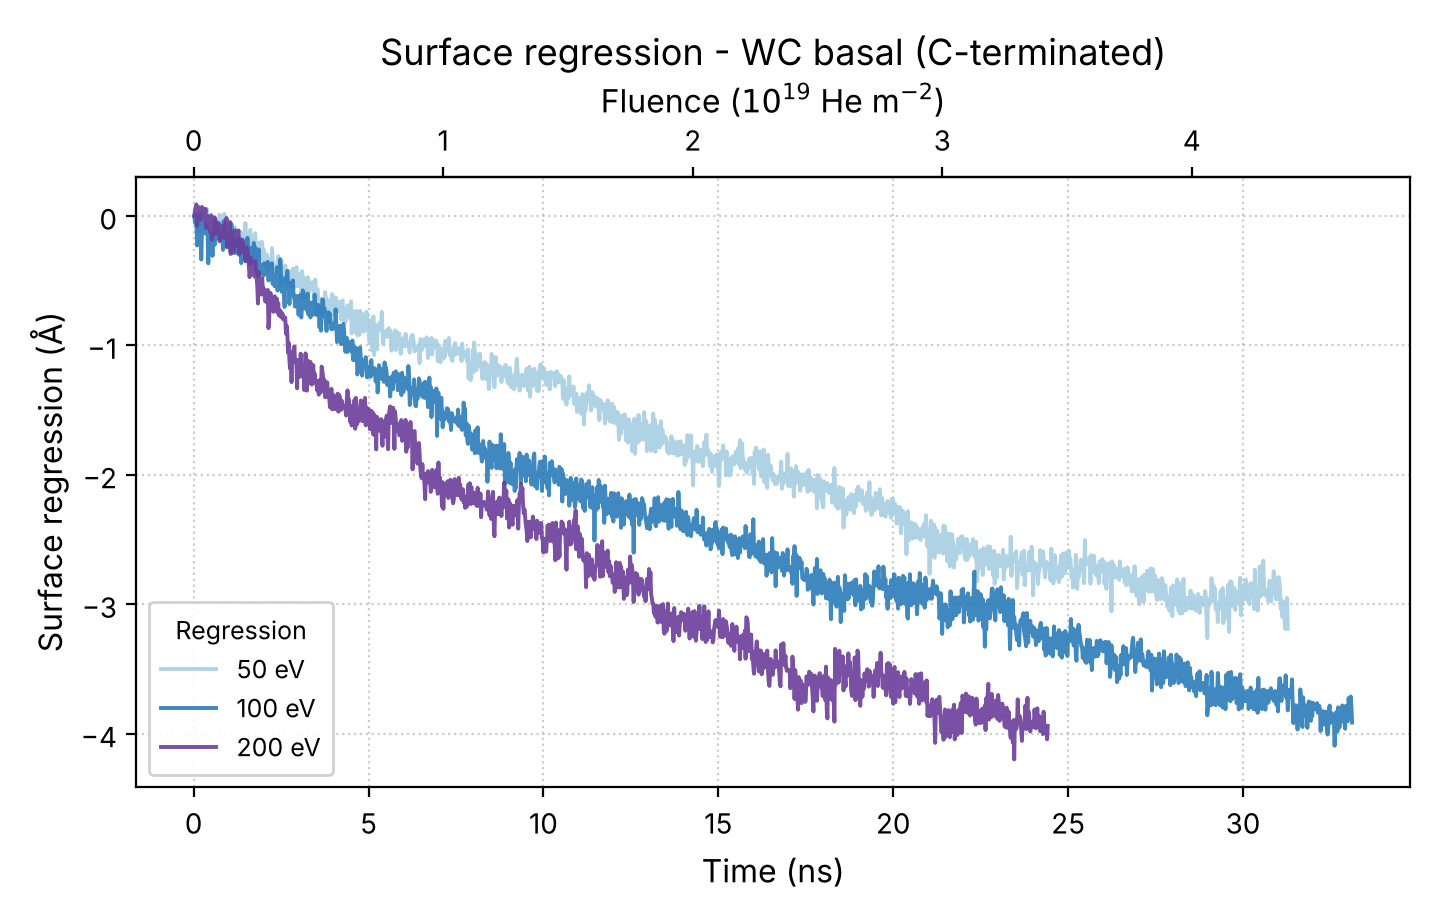

erosion_sputtering_bC.png


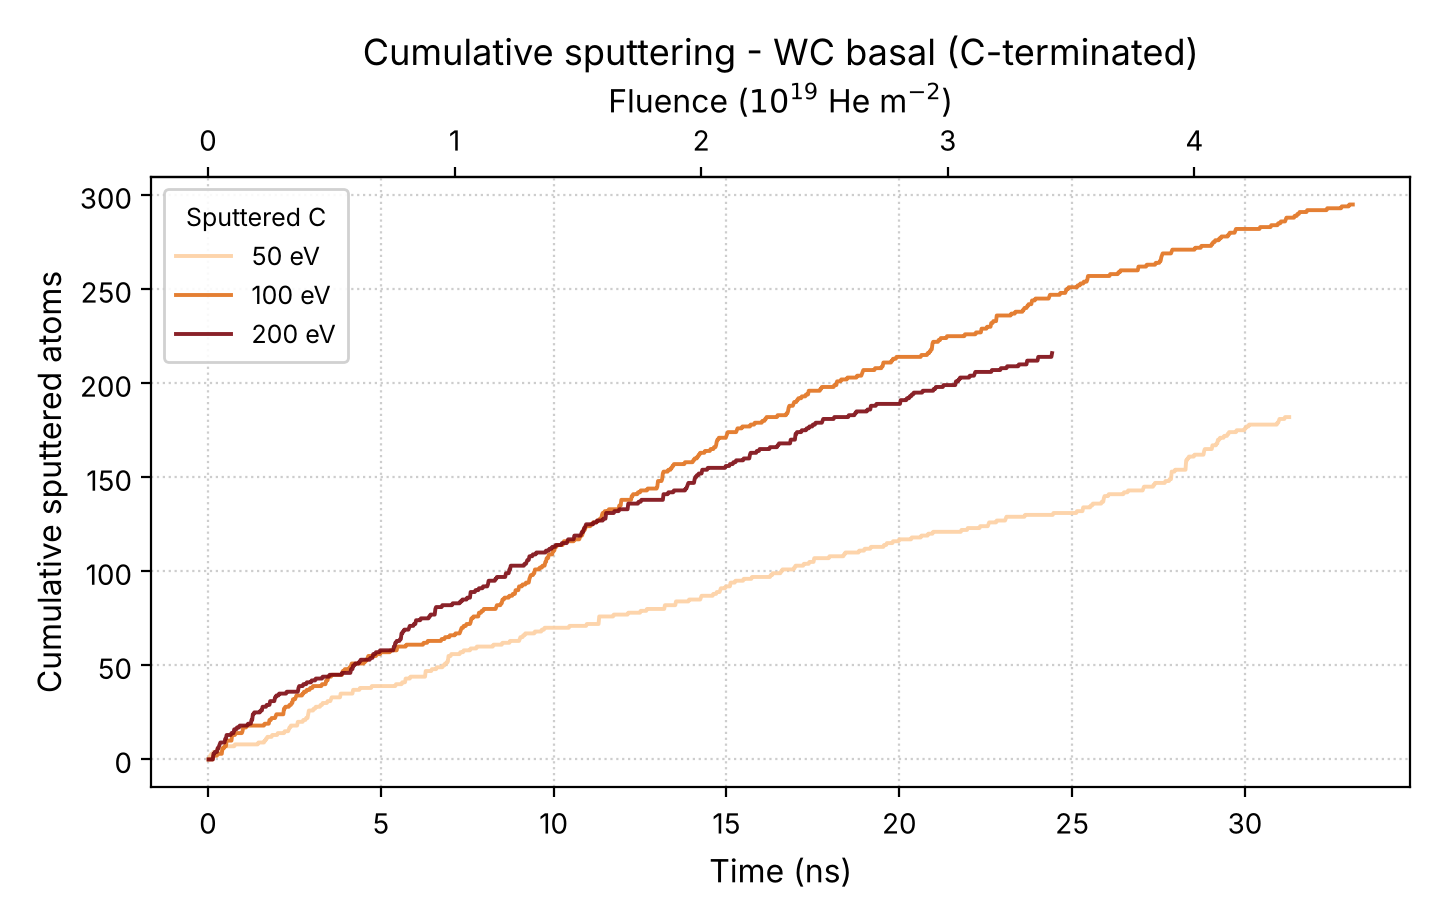

erosion_regression_bW.png


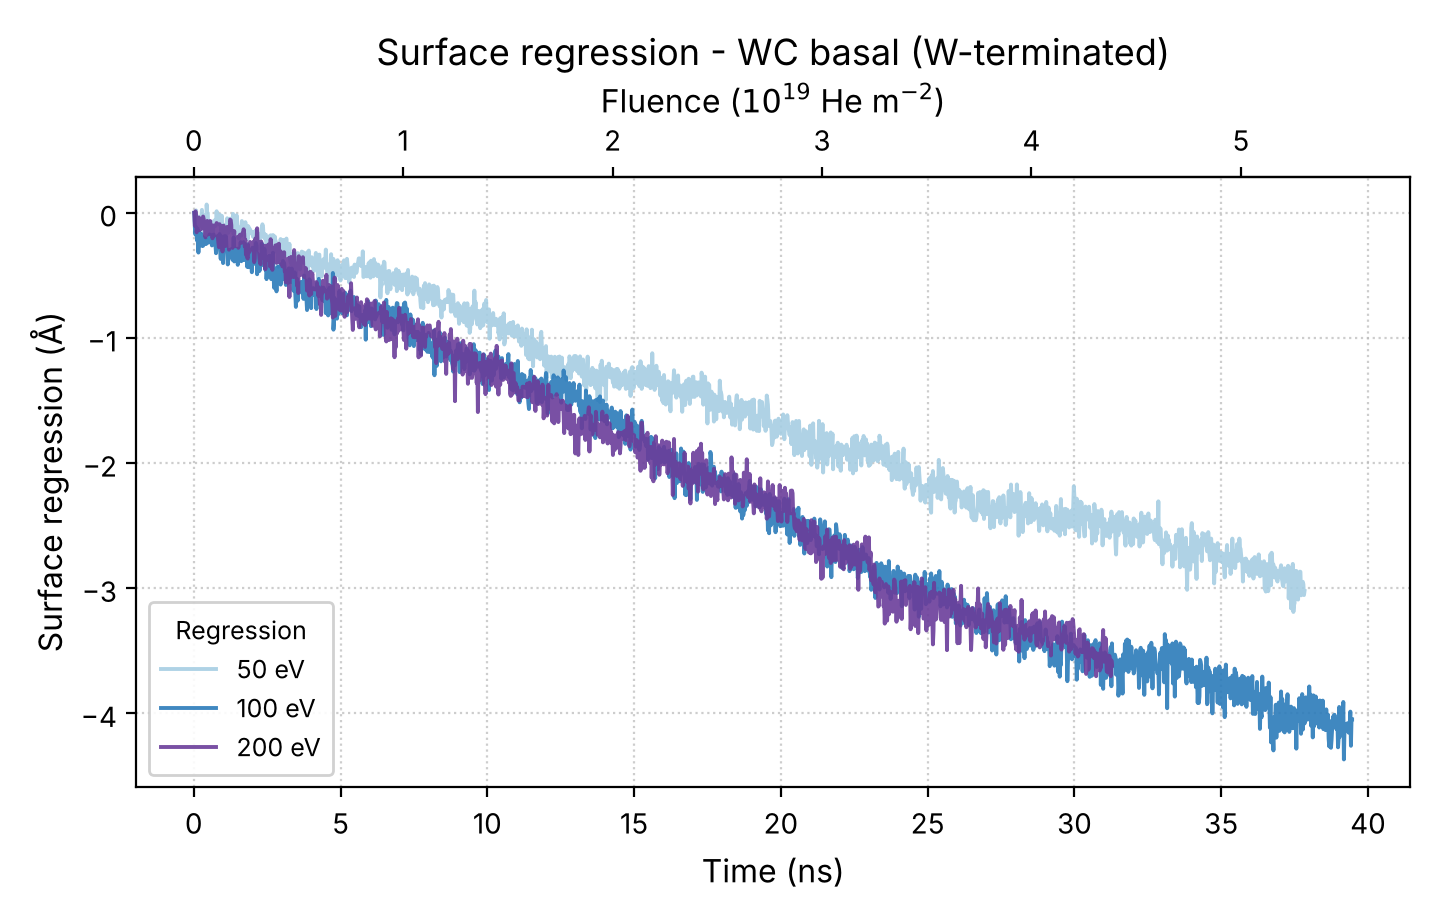

erosion_sputtering_bW.png


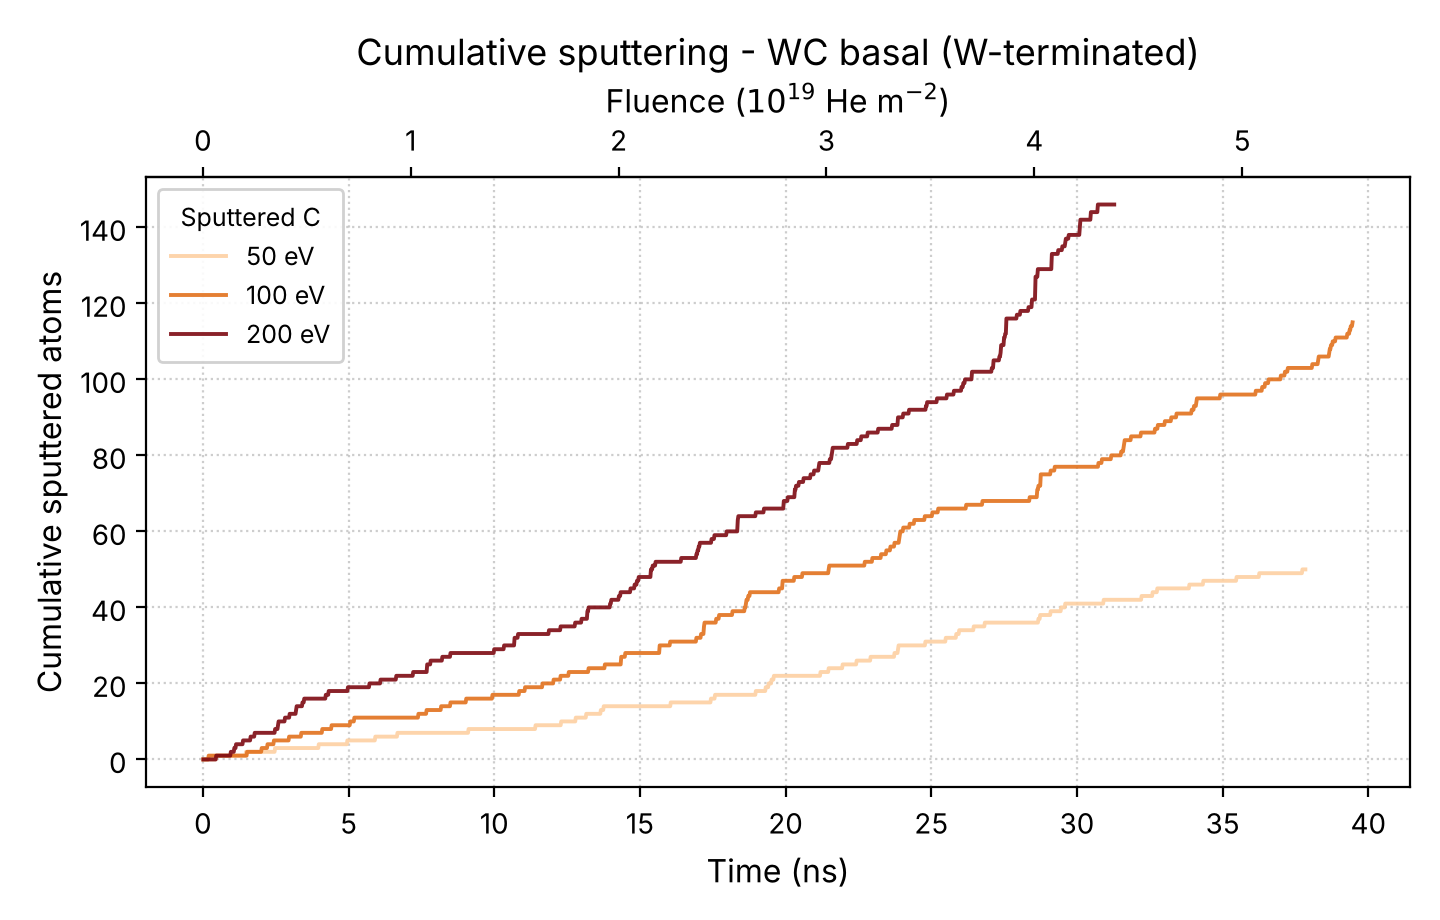

erosion_regression_pr.png


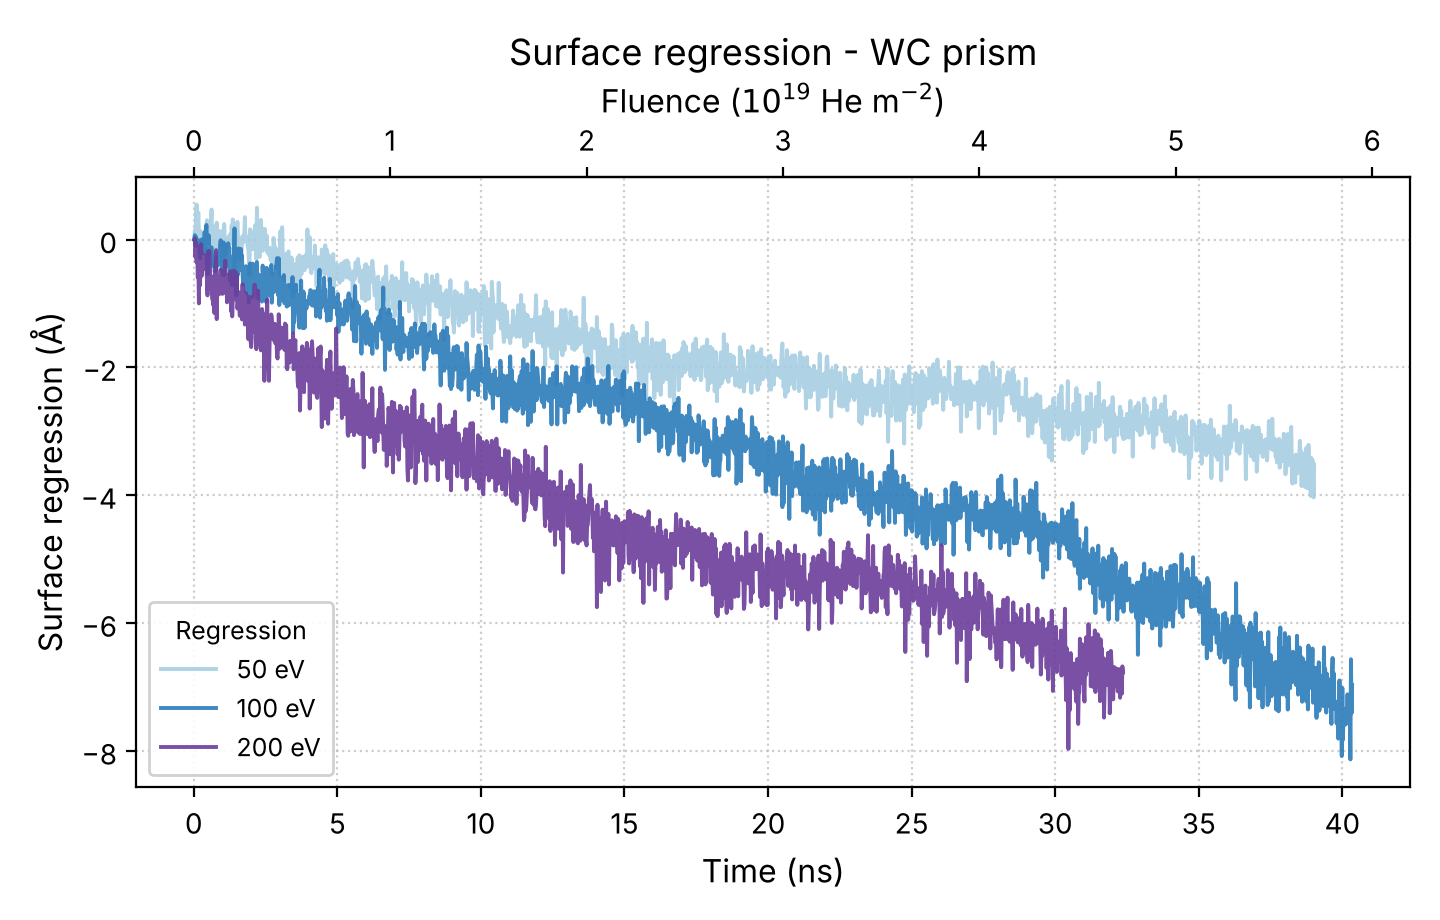

erosion_sputtering_pr.png


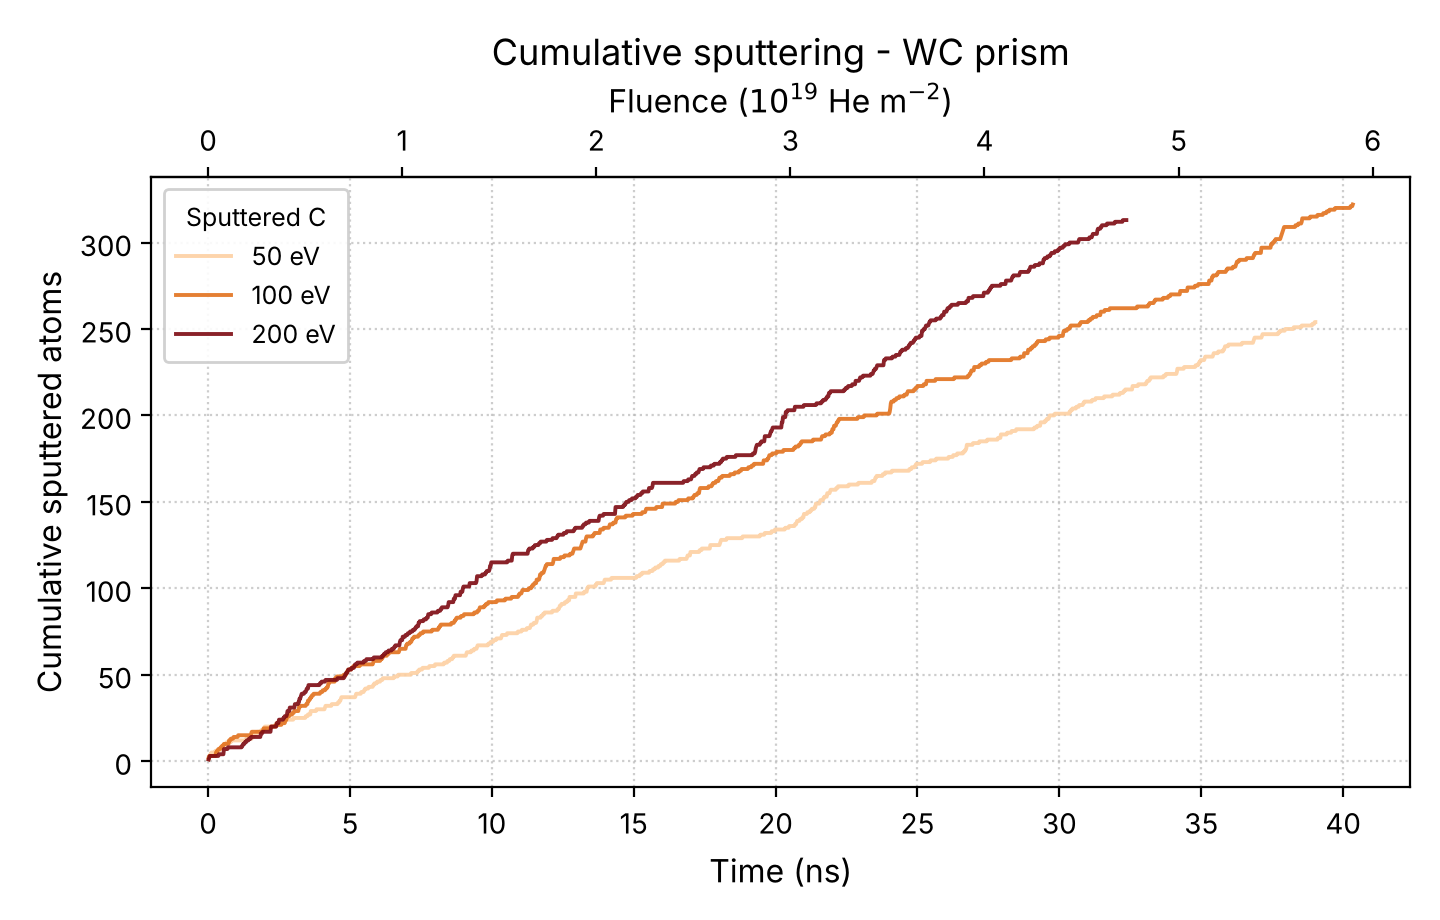

erosion_regression_W001.png


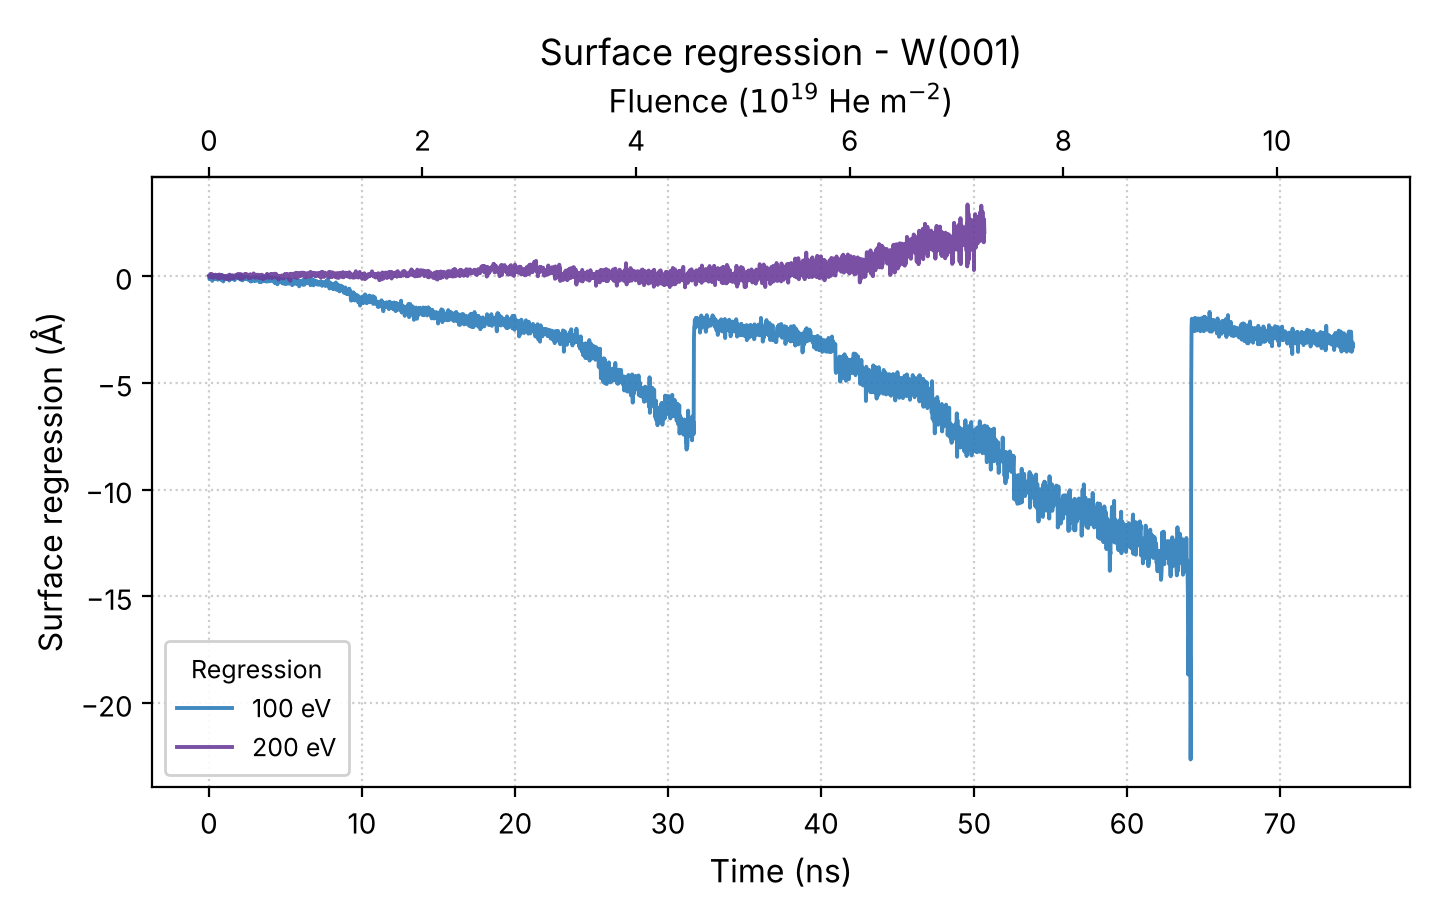

erosion_sputtering_W001.png


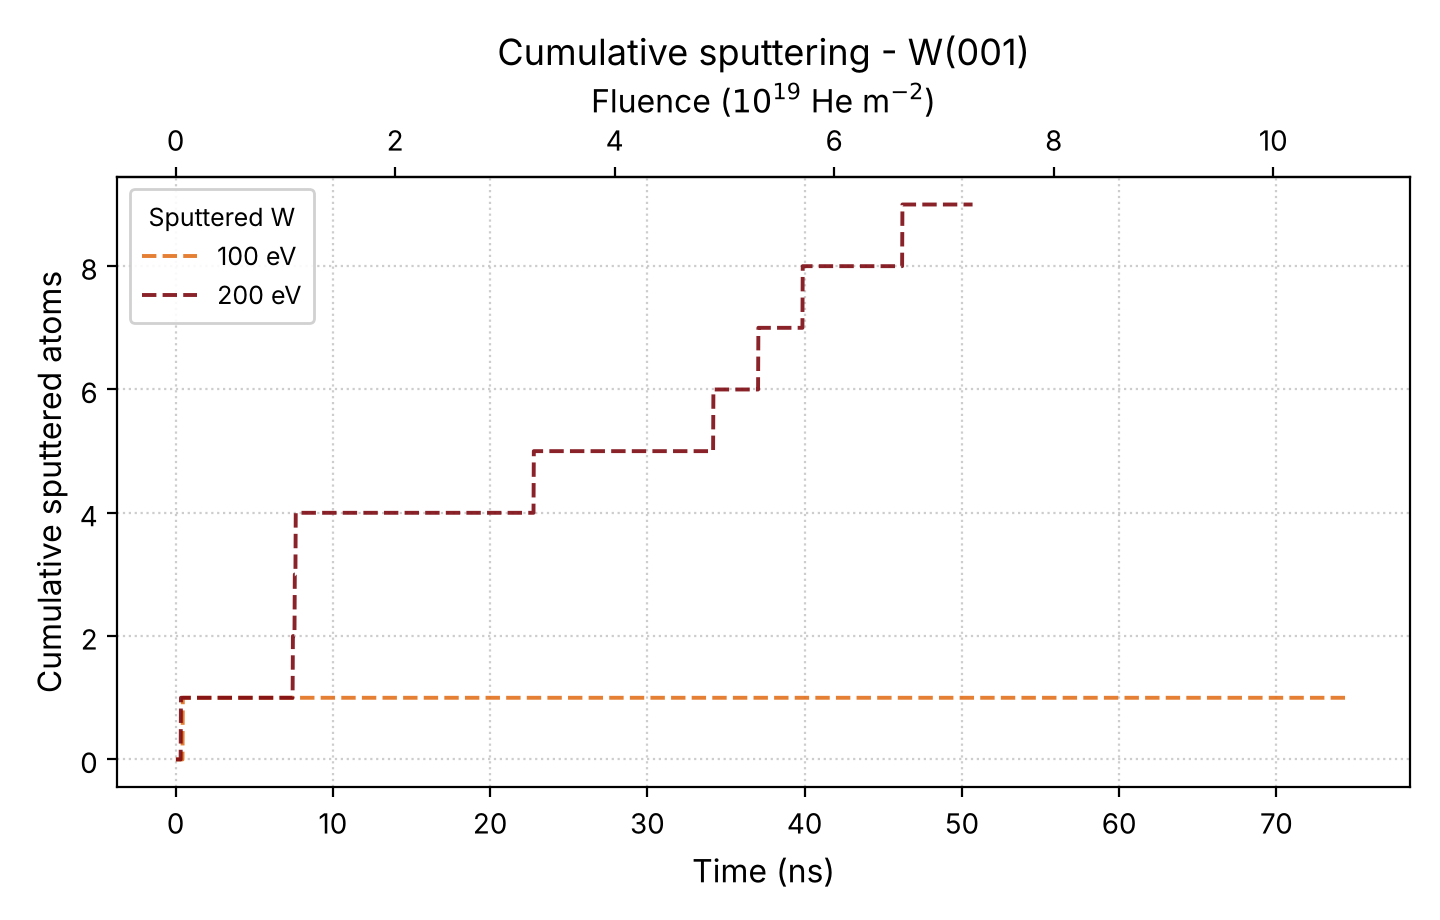

In [28]:
show(NB_OUT, ['erosion_regression_bC.png', 'erosion_sputtering_bC.png', 'erosion_regression_bW.png', 'erosion_sputtering_bW.png', 'erosion_regression_pr.png', 'erosion_sputtering_pr.png', 'erosion_regression_W001.png', 'erosion_sputtering_W001.png'])